# EC3 – Parte 1, pregunta 2: *backflip* de un cuadrúpedo (modelo multicuerpo completo)

Como movimiento libre "interesante" se genera un **mortal hacia atrás de 360°** del **Unitree Go2**. Es un movimiento muy dinámico:

* tiene fases de apoyo con distintos contactos, una fase de vuelo y un **impacto** al aterrizar;
* hay que generar el momento angular suficiente para dar la vuelta completa **sin superar los límites de torque reales** del robot;
* el robot debe **mover las patas en el aire** para controlar su rotación y aterrizar de pie.

A diferencia de la pregunta 1 (SRBM), aquí se usa el **modelo dinámico completo** (las patas tienen masa e inercia, las entradas son los **torques articulares**) y otra transcripción: **colocación directa Hermite–Simpson** (como en el ejemplo `08-4` del acrobot), resuelta con IPOPT mediante CasADi. Los parámetros se leen del URDF (`go2_modelo.py`).

In [1]:
import os
import time
import numpy as np
import casadi as ca
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Polygon
from scipy.interpolate import CubicHermiteSpline
from IPython.display import Image, display

import go2_modelo as go2          # parámetros del Go2 leídos del URDF

FIG = "figuras"
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

## 1. Parámetros del modelo plano (leídos del URDF)

El backflip ocurre en el plano sagital, así que se usa un modelo plano en el que cada "pata" representa el **par izquierda/derecha** (masas, inercias y torques máximos multiplicados por 2). El tronco incluye la base y los 4 motores de abducción (la abducción queda fija). La función `go2.parametros_planos()` obtiene todo del URDF: masas y centros de masa de `base`, `*_hip`, `*_thigh`, `*_calf` y `*_foot`, longitudes de los orígenes de `*_calf_joint` y `*_foot_joint`, y límites de los `<limit>`.

In [2]:
par = go2.parametros_planos()
g = go2.G
m_t, cx_t, I_t = par["m_t"], par["cx_t"], par["I_t"]
m1, lc1, I1 = par["m1"], par["lc1"], par["I1"]
m2, lc2, I2 = par["m2"], par["lc2"], par["I2"]
L1, L2, HIP_X, TRONCO = par["L1"], par["L2"], par["HIP_X"], par["TRONCO"]
TAU_MAX, DQ_MAX, Q_MIN, Q_MAX = par["TAU_MAX"], par["DQ_MAX"], par["Q_MIN"], par["Q_MAX"]
M_TOT = m_t + 2 * (m1 + m2)
mu = 0.8

# Postura nominal de pie: pies bajo las caderas
Q_NOM = np.array([0.80, -1.60])
Z_NOM = L1 * np.cos(Q_NOM[0]) + L2 * np.cos(Q_NOM[0] + Q_NOM[1])

for nombre, valor in [("Masa total [kg]", M_TOT), ("Tronco: masa [kg]", m_t), ("Tronco: I_yy [kg m^2]", I_t),
                      ("Par de muslos: masa / lc / I", (m1, lc1, I1)), ("Par de piernas: masa / lc / I", (m2, lc2, I2)),
                      ("Torque máx. (cadera, rodilla) x2 [N m]", TAU_MAX), ("Vel. máx. [rad/s]", DQ_MAX),
                      ("Altura nominal de la base [m]", Z_NOM)]:
    print(f"{nombre:40s}", np.round(valor, 4))

Masa total [kg]                          15.017
Tronco: masa [kg]                        9.633
Tronco: I_yy [kg m^2]                    0.2039
Par de muslos: masa / lc / I             [2.304  0.0327 0.0116]
Par de piernas: masa / lc / I            [0.388  0.1352 0.0028]
Torque máx. (cadera, rodilla) x2 [N m]   [47.4  90.86]
Vel. máx. [rad/s]                        [30.1 15.7]
Altura nominal de la base [m]            0.2968


## 2. Modelo multicuerpo plano

Coordenadas generalizadas (base flotante + 2 patas de 2 eslabones) y entradas:
$$
\mathbf q=\begin{bmatrix}x & z & \theta & q_1^{d} & q_2^{d} & q_1^{t} & q_2^{t}\end{bmatrix}^\top\in\mathbb R^7,\qquad
\boldsymbol\tau=\begin{bmatrix}\tau_1^{d}&\tau_2^{d}&\tau_1^{t}&\tau_2^{t}\end{bmatrix}^\top .
$$
$\theta$ es el cabeceo con la convención del URDF ($\theta>0$: nariz abajo), por lo que el backflip termina en $\theta=-2\pi$.

Las ecuaciones de Lagrange se obtienen **simbólicamente con diferenciación automática** a partir de las energías cinética $T$ y potencial $V$ de los 5 cuerpos (tronco, 2 muslos, 2 piernas):
$$
M(\mathbf q)\ddot{\mathbf q}+\mathbf h(\mathbf q,\dot{\mathbf q})=S^\top\boldsymbol\tau+J_c(\mathbf q)^\top\boldsymbol\lambda,
\qquad
M=\frac{\partial^2T}{\partial\dot{\mathbf q}^2},\quad
\mathbf h=\frac{\partial}{\partial\mathbf q}\Big(\frac{\partial T}{\partial\dot{\mathbf q}}\Big)\dot{\mathbf q}-\frac{\partial T}{\partial\mathbf q}+\frac{\partial V}{\partial\mathbf q},
$$
con $S=[\,0_{4\times3}\ \ I_4\,]$ y $\boldsymbol\lambda=(f_x^d,f_z^d,f_x^t,f_z^t)$ las fuerzas de contacto de los pies.

In [3]:
q = ca.SX.sym("q", 7)
dq = ca.SX.sym("dq", 7)
x_b, z_b, th = q[0], q[1], q[2]


def rot(a, v):
    """Rotación plana (x, z) con la convención de R_y:  x' = c x + s z,  z' = -s x + c z."""
    return ca.vertcat(ca.cos(a) * v[0] + ca.sin(a) * v[1], -ca.sin(a) * v[0] + ca.cos(a) * v[1])


p_b = ca.vertcat(x_b, z_b)
cuerpos = [(m_t, I_t, p_b + rot(th, ca.vertcat(cx_t, 0)), th)]      # (masa, inercia, CdM, ángulo)
puntos = {}
for nombre, sx, iq in (("del", +1, 3), ("tras", -1, 5)):
    a1 = th + q[iq]
    a2 = a1 + q[iq + 1]
    cad = p_b + rot(th, ca.vertcat(sx * HIP_X, 0))
    rod = cad + rot(a1, ca.vertcat(0, -L1))
    pie = rod + rot(a2, ca.vertcat(0, -L2))
    cuerpos.append((m1, I1, cad + rot(a1, ca.vertcat(0, -lc1)), a1))
    cuerpos.append((m2, I2, rod + rot(a2, ca.vertcat(0, -lc2)), a2))
    puntos[nombre] = (cad, rod, pie)

# Energías y ecuaciones de Lagrange (derivación automática)
T_cin, V_pot, p_cm = 0, 0, 0
for mi, Ii, pi, ai in cuerpos:
    vi = ca.jacobian(pi, q) @ dq
    wi = ca.jacobian(ai, q) @ dq
    T_cin += 0.5 * mi * ca.dot(vi, vi) + 0.5 * Ii * wi**2
    V_pot += mi * g * pi[1]
    p_cm += mi * pi / M_TOT
M = ca.jacobian(ca.gradient(T_cin, dq), dq)
h = ca.jacobian(ca.gradient(T_cin, dq), q) @ dq - ca.gradient(T_cin, q) + ca.gradient(V_pot, q)
S = ca.horzcat(ca.DM.zeros(4, 3), ca.DM.eye(4))      # matriz de selección de actuadores

# Momento angular centroidal (para verificar su conservación en vuelo)
H_cm = 0
for mi, Ii, pi, ai in cuerpos:
    vi = ca.jacobian(pi, q) @ dq
    wi = ca.jacobian(ai, q) @ dq
    r = pi - p_cm
    H_cm += Ii * wi + mi * (r[1] * vi[0] - r[0] * vi[1])   # mismo sentido que theta

u = ca.SX.sym("u", 4)
x = ca.vertcat(q, dq)
pie_del, pie_tras = puntos["del"][2], puntos["tras"][2]
p_pies = ca.vertcat(pie_del, pie_tras)
Jc_sx = ca.vertcat(ca.jacobian(pie_del, q), ca.jacobian(pie_tras, q))      # 4x7
dJdq_sx = ca.jacobian(Jc_sx @ dq, q) @ dq

# Funciones numéricas
F_M = ca.Function("M", [q], [M])
F_h = ca.Function("h", [x], [h])
F_Jc = ca.Function("Jc", [q], [Jc_sx])
F_dJdq = ca.Function("dJdq", [x], [dJdq_sx])
F_pies = ca.Function("pies", [q], [p_pies])
F_vpies = ca.Function("v_pies", [x], [Jc_sx @ dq])
F_puntos = ca.Function("puntos", [q], [ca.horzcat(puntos["del"][0], puntos["del"][1], pie_del,
                                                  puntos["tras"][0], puntos["tras"][1], pie_tras)])
F_cm = ca.Function("cm", [q], [p_cm])
F_H = ca.Function("H", [x], [H_cm])
esq = [rot(th, ca.vertcat(sx * TRONCO[0] / 2, sz * TRONCO[1] / 2)) + p_b for sx in (1, -1) for sz in (1, -1)]
F_esq = ca.Function("esquinas", [q], [ca.horzcat(*esq)])
S_np = np.array(S)

x0 = np.r_[0, Z_NOM, 0, Q_NOM, Q_NOM, np.zeros(7)]
print("Autovalores de M(q0):", np.round(np.linalg.eigvalsh(np.array(F_M(x0[:7]))), 4))

Autovalores de M(q0): [6.50000e-03 6.80000e-03 3.31000e-02 4.34000e-02 4.91300e-01 1.50177e+01
 1.50262e+01]


## 3. Contactos e impacto

**Dinámica de contacto con estabilización de Baumgarte.** En apoyo, el pie $c$ está fijo en $\mathbf p_c^\star$. La condición se impone a nivel de aceleración con estabilización de Baumgarte ($\alpha=10$) para evitar la deriva:
$$
J_c\ddot{\mathbf q}+\dot J_c\dot{\mathbf q}+2\alpha J_c\dot{\mathbf q}+\alpha^2\big(\mathbf p_c(\mathbf q)-\mathbf p_c^\star\big)=\mathbf 0,\qquad f_z\ge0,\quad |f_x|\le\mu f_z .
$$
Junto con la ecuación de Lagrange forma el sistema KKT
$$
\begin{bmatrix}M & -J_c^\top\\ J_c & 0\end{bmatrix}\begin{bmatrix}\ddot{\mathbf q}\\ \boldsymbol\lambda\end{bmatrix}
=\begin{bmatrix}S^\top\boldsymbol\tau-\mathbf h\\ -\dot J_c\dot{\mathbf q}-2\alpha J_c\dot{\mathbf q}-\alpha^2(\mathbf p_c-\mathbf p_c^\star)\end{bmatrix},
$$
que se resuelve numéricamente en la simulación. **En el NLP no se invierte**: $\ddot{\mathbf q}$ y $\boldsymbol\lambda$ son variables y las dos ecuaciones son restricciones (*dinámica implícita*), lo que mantiene el problema disperso y rápido.

**Impacto al aterrizar.** Se modela como un impacto plástico (los pies quedan con velocidad nula):
$$
\dot{\mathbf q}^+=\dot{\mathbf q}^-+M^{-1}J_c^\top\mathbf P,\qquad
\mathbf P=-\big(J_cM^{-1}J_c^\top\big)^{-1}J_c\dot{\mathbf q}^- ,
$$
con el impulso $\mathbf P$ unilateral y dentro del cono de fricción. (Exigir un aterrizaje con velocidad nula de los pies resultó infactible: con el cuerpo girando a ~13 rad/s las patas tendrían que superar el límite de velocidad de la rodilla.)

In [4]:
ALFA = 10.0
a_s = ca.SX.sym("a", 7)          # aceleraciones generalizadas
lam_s = ca.SX.sym("lam", 4)      # [fx_del, fz_del, fx_tras, fz_tras]
pc_s = ca.SX.sym("pc", 4)        # puntos de contacto

# Residuos de la dinámica implícita (restricciones del NLP)
R_din = ca.Function("R_din", [x, u, a_s, lam_s], [M @ a_s + h - S.T @ u - Jc_sx.T @ lam_s])
R_con = ca.Function("R_con", [x, a_s, pc_s],
                    [Jc_sx @ a_s + dJdq_sx + 2 * ALFA * Jc_sx @ dq + ALFA**2 * (p_pies - pc_s)])

# Mapa de impacto plástico con ambos pies
MiJt = ca.solve(M, Jc_sx.T)
P_imp = -ca.solve(Jc_sx @ MiJt, Jc_sx @ dq)
F_impacto = ca.Function("impacto", [x], [ca.vertcat(q, dq + MiJt @ P_imp), P_imp])


def dinamica_numerica(xv, uv, contacto, pc):
    """ddq y lambda resolviendo el sistema KKT numéricamente (para la simulación)."""
    qv = xv[:7]
    Mv, hv = np.array(F_M(qv)), np.array(F_h(xv)).ravel()
    idx = [j for c in range(2) if contacto[c] for j in (2 * c, 2 * c + 1)]
    if not idx:
        return np.linalg.solve(Mv, S_np.T @ uv - hv), np.zeros(4)
    Jall = np.array(F_Jc(qv))
    dv = (np.array(F_dJdq(xv)).ravel() + 2 * ALFA * Jall @ xv[7:]
          + ALFA**2 * (np.array(F_pies(qv)).ravel() - pc))[idx]
    Jv, n = Jall[idx], len(idx)
    K = np.block([[Mv, -Jv.T], [Jv, np.zeros((n, n))]])
    sol_k = np.linalg.solve(K, np.r_[S_np.T @ uv - hv, -dv])
    lam = np.zeros(4)
    lam[idx] = sol_k[7:]
    return sol_k[:7], lam


# Comprobación: torques estáticos que mantienen al robot de pie (ddq = 0 con ambos pies apoyados)
PIES_INI = np.array(F_pies(x0[:7])).ravel()
a0, _ = dinamica_numerica(x0, np.zeros(4), (1, 1), PIES_INI)
Ja = np.column_stack([dinamica_numerica(x0, e, (1, 1), PIES_INI)[0] - a0 for e in np.eye(4)])
u_est = -np.linalg.lstsq(Ja, a0, rcond=None)[0]
a_est, lam_est = dinamica_numerica(x0, u_est, (1, 1), PIES_INI)
print("Torques estáticos [N m]:", np.round(u_est, 3), "| |ddq| =", f"{np.abs(a_est).max():.1e}")
print("Fuerzas de contacto [N]:", np.round(lam_est, 2), f"(peso/2 = {M_TOT * g / 2:.2f} N)")

Torques estáticos [N m]: [ 0.751 10.869  0.734 10.902] | |ddq| = 1.2e-13
Fuerzas de contacto [N]: [ 3.000e-02  7.352e+01 -3.000e-02  7.379e+01] (peso/2 = 73.66 N)


## 4. Formulación del NLP: colocación directa Hermite–Simpson

| Fase | Descripción | Contactos | $N_j$ | $T_j$ [s] |
|---|---|---|---|---|
| 1 | Impulso con 4 patas | delantera y trasera | 20 | [0.20, 0.70] |
| 2 | Impulso con traseras | trasera | 16 | [0.08, 0.40] |
| 3 | Vuelo, giro de 360° | — | 30 | [0.25, 0.80] |
| — | Impacto | mapa de impacto | — | — |
| 4 | Aterrizaje y estabilización | delantera y trasera | 24 | [0.30, 0.80] |

En cada intervalo se optimizan los estados nodales $\mathbf x_k=(\mathbf q_k,\dot{\mathbf q}_k)$, el estado en el punto medio $\mathbf x_{c,k}$, el torque $\boldsymbol\tau_k$ (constante en el intervalo) y, por la dinámica implícita, las aceleraciones $\mathbf a$ y fuerzas $\boldsymbol\lambda$ en los tres puntos de colocación, con $\mathbf f=(\dot{\mathbf q},\mathbf a)$:
$$
\begin{aligned}
\min\quad & \sum_k h_k\Big[\|\boldsymbol\tau_k\oslash\boldsymbol\tau_{\max}\|^2+10^{-3}\|\dot{\mathbf q}_{a,k}\|^2\Big]+0.05\sum_k\|(\boldsymbol\tau_k-\boldsymbol\tau_{k-1})\oslash\boldsymbol\tau_{\max}\|^2+\tfrac12\|J_c\dot{\mathbf q}^-\|^2\\
\text{s.a.}\quad & \mathbf x_{c,k}=\tfrac12(\mathbf x_k+\mathbf x_{k+1})+\tfrac{h_k}{8}(\mathbf f_k-\mathbf f_{k+1}),\qquad
\mathbf x_{k+1}=\mathbf x_k+\tfrac{h_k}{6}(\mathbf f_k+4\mathbf f_{c,k}+\mathbf f_{k+1})\\
& M\mathbf a+\mathbf h=S^\top\boldsymbol\tau+J_c^\top\boldsymbol\lambda,\ \ \text{contacto con Baumgarte y fricción (en los 3 puntos)}\\
& |\tau_1|\le\tau_{1,\max},\ |\tau_2|\le\tau_{2,\max},\quad \mathbf q_{\min}\le\mathbf q_a\le\mathbf q_{\max},\quad |\dot q_i|\le\dot q_{i,\max}\\
& z_{\rm rodillas}\ge0.02,\quad z_{\rm esquinas\ tronco}\ge0.04,\quad z_{\rm pie\ en\ el\ aire}\ge0\\
& \text{aterrizaje: } z_{\rm pies}=0,\ \dot z^-_{\rm pies}\le0,\ \mathbf P\text{ admisible},\ x^a_d-x^a_t=2\,x_{\rm cadera}\\
& \text{final: } z=z_{\rm nom},\ \theta=-2\pi,\ \dot x=\dot z=\dot\theta=0 .
\end{aligned}
$$
Con los dos pies apoyados el sistema sólo tiene 3 GDL: al final se imponen sólo $(z,\theta)$, sus velocidades y la separación nominal de los pies. Imponer además los ángulos articulares finales deja el jacobiano de restricciones casi singular e IPOPT no converge.

In [5]:
CONTACTO = {"ambas": (1, 1), "tras": (0, 1), "vuelo": (0, 0)}      # (delantera, trasera)
FASES = [
    dict(nombre="Apoyo 4 patas (impulso)",    modo="ambas", N=20, T=(0.20, 0.70), T0=0.40),
    dict(nombre="Apoyo patas traseras",        modo="tras",  N=16, T=(0.08, 0.40), T0=0.18),
    dict(nombre="Vuelo (giro de 360°)",        modo="vuelo", N=30, T=(0.25, 0.80), T0=0.45),
    dict(nombre="Aterrizaje 4 patas",          modo="ambas", N=24, T=(0.30, 0.80), T0=0.50),
]
NF = len(FASES)
TH_FIN = -2 * np.pi
TAU_VEC = ca.DM(np.r_[TAU_MAX, TAU_MAX])

opti = ca.Opti()
T_f = opti.variable(NF)
x_aterr = opti.variable(2)             # x de los pies delantero / trasero al aterrizar
X_f, Xc_f, U_f, A_f, L_f = [], [], [], [], []
J = 0
x_prev = ca.DM(x0)
for fi, fase in enumerate(FASES):
    N, cont = fase["N"], CONTACTO[fase["modo"]]
    hk = T_f[fi] / N
    if fi == 3:                                     # aterrizaje: mapa de impacto
        x_menos = x_prev
        x_prev, P_impulso = F_impacto(x_menos)
    X = ca.horzcat(x_prev, opti.variable(14, N))
    pc_fase = ca.DM(PIES_INI) if fi < 3 else ca.vertcat(x_aterr[0], 0, x_aterr[1], 0)
    Xc = opti.variable(14, N)
    U = opti.variable(4, N)
    A = opti.variable(7, 3 * N)                     # aceleraciones en (izq, medio, der) de cada intervalo
    nl = 2 * sum(cont)
    Lv = opti.variable(nl, 3 * N) if nl else None   # fuerzas de contacto en los mismos puntos
    X_f.append(X); Xc_f.append(Xc); U_f.append(U); A_f.append(A); L_f.append(Lv)

    def lam_completo(col):
        """Vector lambda de 4 componentes (ceros para los pies en el aire)."""
        partes, j = [], 0
        for c in range(2):
            if cont[c]:
                partes.append(Lv[j:j + 2, col]); j += 2
            else:
                partes.append(ca.DM.zeros(2, 1))
        return ca.vertcat(*partes)

    for k in range(N):
        xk, xk1, xm, uk = X[:, k], X[:, k + 1], Xc[:, k], U[:, k]
        ders = []
        for j, xe in enumerate((xk, xm, xk1)):
            col = 3 * k + j
            ae, le = A[:, col], lam_completo(col)
            # --- dinámica de Lagrange (implícita) y contacto con Baumgarte
            opti.subject_to(R_din(xe, uk, ae, le) == 0)
            rc = R_con(xe, ae, pc_fase)
            for c in range(2):
                if cont[c]:
                    opti.subject_to(rc[2 * c:2 * c + 2] == 0)
                    fx, fz = le[2 * c], le[2 * c + 1]
                    opti.subject_to(fz >= 0)
                    opti.subject_to(opti.bounded(-mu * fz, fx, mu * fz))
            ders.append(ca.vertcat(xe[7:], ae))
        fk, fm, fk1 = ders
        # --- Hermite-Simpson (forma separada, como en la clase 08-4)
        opti.subject_to(xm == (xk + xk1) / 2 + hk / 8 * (fk - fk1))
        opti.subject_to(xk1 == xk + hk / 6 * (fk + 4 * fm + fk1))
        # --- límites articulares, de velocidad y geometría
        for xe in (xm, xk1):
            qe = xe[:7]
            for iq in (3, 5):
                opti.subject_to(opti.bounded(Q_MIN[0], qe[iq], Q_MAX[0]))
                opti.subject_to(opti.bounded(Q_MIN[1], qe[iq + 1], Q_MAX[1]))
                opti.subject_to(opti.bounded(-DQ_MAX[0], xe[7 + iq], DQ_MAX[0]))
                opti.subject_to(opti.bounded(-DQ_MAX[1], xe[7 + iq + 1], DQ_MAX[1]))
            P = F_puntos(qe)
            opti.subject_to(P[1, 1] >= 0.02)                            # rodillas sobre el suelo
            opti.subject_to(P[1, 4] >= 0.02)
            if not cont[0]:
                opti.subject_to(P[1, 2] >= 0.0)                         # pie delantero en el aire
            if not cont[1]:
                opti.subject_to(P[1, 5] >= 0.0)                         # pie trasero en el aire
            E = F_esq(qe)
            for c in range(4):
                opti.subject_to(E[1, c] >= 0.04)                        # tronco sobre el suelo
        for j in range(4):
            opti.subject_to(opti.bounded(-TAU_MAX[j % 2], uk[j], TAU_MAX[j % 2]))
        # --- costo: esfuerzo normalizado + suavidad
        un = uk / TAU_VEC
        J += hk * (ca.sumsqr(un) + 1e-3 * ca.sumsqr(xk[10:14]))
        if k > 0:
            J += 0.05 * ca.sumsqr(un - U[:, k - 1] / TAU_VEC)
    x_prev = X[:, -1]
    opti.subject_to(opti.bounded(fase["T"][0], T_f[fi], fase["T"][1]))

# --- Aterrizaje: pies en el suelo, impacto físicamente admisible
P_td = F_puntos(x_menos[:7])
opti.subject_to(P_td[1, 2] == 0)
opti.subject_to(P_td[1, 5] == 0)
opti.subject_to(P_td[0, 2] == x_aterr[0])
opti.subject_to(P_td[0, 5] == x_aterr[1])
v_td = F_vpies(x_menos)                            # velocidades de los pies justo antes del contacto
opti.subject_to(v_td[1] <= 0)
opti.subject_to(v_td[3] <= 0)
for c in range(2):                                 # impulso unilateral y dentro del cono de fricción
    opti.subject_to(P_impulso[2 * c + 1] >= 0)
    opti.subject_to(opti.bounded(-mu * P_impulso[2 * c + 1], P_impulso[2 * c], mu * P_impulso[2 * c + 1]))
J += 0.5 * ca.sumsqr(v_td)                         # aterrizaje suave
opti.subject_to(x_aterr[0] - x_aterr[1] == 2 * HIP_X)
# --- Estado final: de pie y en reposo, tras una vuelta completa (3 GDL independientes)
x_fin = X_f[-1][:, -1]
opti.subject_to(x_fin[1] == Z_NOM)
opti.subject_to(x_fin[2] == TH_FIN)
opti.subject_to(x_fin[7:10] == 0)
opti.minimize(J)
print(f"Variables: {opti.nx} | restricciones: {opti.ng}")

Variables: 5400 | restricciones: 9024


## 5. Estimación inicial y solución

La estimación inicial es muy simple: el tronco gira linealmente durante el vuelo, el CdM sigue un arco y las patas permanecen en la postura nominal (no es factible). IPOPT tarda unos 2–3 minutos.

In [6]:
T0s = np.array([f["T0"] for f in FASES])
lim0 = np.r_[0, np.cumsum(T0s)]


def guia(t):
    """Trayectoria guía: impulso, rotación lineal en vuelo, aterrizaje."""
    th_g = np.interp(t, [0, lim0[1], lim0[2], lim0[3], lim0[4]],
                     [0, -0.3, -0.9, TH_FIN + 0.3, TH_FIN])
    s = np.clip((t - lim0[2]) / T0s[2], 0, 1)
    z_g = np.interp(t, [0, lim0[1] * 0.7, lim0[1], lim0[2], lim0[3], lim0[4]],
                    [Z_NOM, Z_NOM - 0.08, Z_NOM, Z_NOM + 0.06, Z_NOM + 0.06, Z_NOM]) + 0.25 * np.sin(np.pi * s)
    x_g = np.interp(t, [0, lim0[2], lim0[3], lim0[4]], [0, 0.0, -0.25, -0.25])
    return np.r_[x_g, z_g, th_g, Q_NOM, Q_NOM]


for fi, fase in enumerate(FASES):
    N, cont = fase["N"], CONTACTO[fase["modo"]]
    opti.set_initial(T_f[fi], fase["T0"])
    tn = lim0[fi] + np.linspace(0, T0s[fi], N + 1)
    tm = (tn[:-1] + tn[1:]) / 2
    qg = np.array([guia(t) for t in tn]).T
    qm = np.array([guia(t) for t in tm]).T
    dqg = np.gradient(qg, tn, axis=1)
    dqm = np.array([(guia(t + 1e-3) - guia(t - 1e-3)) / 2e-3 for t in tm]).T
    opti.set_initial(X_f[fi][:, 1:], np.vstack([qg, dqg])[:, 1:])
    opti.set_initial(Xc_f[fi], np.vstack([qm, dqm]))
    opti.set_initial(U_f[fi], 0)
    opti.set_initial(A_f[fi], 0)
    if L_f[fi] is not None:
        lg = np.zeros((L_f[fi].shape[0], 3 * N))
        lg[1::2] = M_TOT * g / sum(cont)
        opti.set_initial(L_f[fi], lg)
opti.set_initial(x_aterr, [-0.25 + HIP_X, -0.25 - HIP_X])

opti.solver("ipopt", {"expand": True, "print_time": False},
            {"print_level": 0, "max_iter": 4000, "tol": 1e-6, "acceptable_tol": 1e-4,
             "mu_strategy": "adaptive"})
t_ini = time.time()
sol = opti.solve()
print(f"IPOPT: {sol.stats()['return_status']} | iteraciones: {sol.stats()['iter_count']} "
      f"| tiempo: {time.time() - t_ini:.1f} s | costo: {sol.value(J):.4f}")


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************



IPOPT: Solved_To_Acceptable_Level | iteraciones: 2169 | tiempo: 202.8 s | costo: 2.4850


## 6. Recuperación de la solución

In [7]:
T_opt = np.array(sol.value(T_f)).ravel()
lim = np.r_[0, np.cumsum(T_opt)]
t_n, x_n, u_n, modo_n, lam_n = [0.0], [x0], [], [], []
for fi, fase in enumerate(FASES):
    N, cont = fase["N"], CONTACTO[fase["modo"]]
    hk = T_opt[fi] / N
    Xv = np.array(sol.value(X_f[fi]))
    Uv = np.array(sol.value(U_f[fi])).reshape(4, N)
    Lv = np.array(sol.value(L_f[fi])).reshape(-1, 3 * N) if L_f[fi] is not None else None
    for k in range(N):
        lam = np.zeros(4)
        if Lv is not None:
            j = 0
            for c in range(2):
                if cont[c]:
                    lam[2 * c:2 * c + 2] = Lv[j:j + 2, 3 * k]; j += 2
        t_n.append(lim[fi] + (k + 1) * hk); x_n.append(Xv[:, k + 1])
        u_n.append(Uv[:, k]); modo_n.append(fi); lam_n.append(lam)
t_n, x_n, u_n = np.array(t_n), np.array(x_n).T, np.array(u_n).T
modo_n, lam_n = np.array(modo_n), np.array(lam_n).T
H_n = np.array([float(F_H(x_n[:, k])) for k in range(x_n.shape[1])])
cm_n = np.array([np.array(F_cm(x_n[:7, k])).ravel() for k in range(x_n.shape[1])]).T

print("Duración de las fases [s]:", np.round(T_opt, 3), "| total:", round(T_opt.sum(), 3))
print(f"Rotación total: {np.degrees(x_n[2, -1]):.1f}° | desplazamiento x: {x_n[0, -1]:.3f} m")
print(f"Altura máx. del CdM: {cm_n[1].max():.3f} m | máx. |theta_dot|: {np.abs(x_n[9]).max():.2f} rad/s")
print("Velocidad de los pies al aterrizar [m/s] (vx, vz del., vx, vz tras.):",
      np.round(np.array(sol.value(v_td)).ravel(), 3))
print("Impulso de impacto [N s] (Px, Pz del., Px, Pz tras.):", np.round(np.array(sol.value(P_impulso)).ravel(), 3))
print(f"Torque máx. cadera / rodilla (par de patas): {np.abs(u_n[[0, 2]]).max():.1f} / "
      f"{np.abs(u_n[[1, 3]]).max():.1f} N m  (límites {TAU_MAX})")

Duración de las fases [s]: [0.623 0.4   0.422 0.699] | total: 2.144
Rotación total: -360.0° | desplazamiento x: -0.542 m
Altura máx. del CdM: 0.481 m | máx. |theta_dot|: 11.96 rad/s
Velocidad de los pies al aterrizar [m/s] (vx, vz del., vx, vz tras.): [ 0.102 -0.127 -0.494 -1.828]
Impulso de impacto [N s] (Px, Pz del., Px, Pz tras.): [-0.087  0.123 -0.333  1.06 ]
Torque máx. cadera / rodilla (par de patas): 47.4 / 90.9 N m  (límites [47.4  90.86])


## 7. Verificación

1. **Deriva de los pies de apoyo** (el contacto se impone a nivel de aceleración).
2. **Conservación del momento angular centroidal en vuelo** (dinámica centroidal sin fuerzas externas: $\dot{\mathbf h}_{cm}=0$).
3. **Simulación independiente** con RK4 fino (20 subpasos por intervalo), la misma secuencia de contactos, el mapa de impacto y $\ddot{\mathbf q},\boldsymbol\lambda$ obtenidos del sistema KKT:
   * (a) **lazo abierto:** $\boldsymbol\tau=\boldsymbol\tau^*(t)$;
   * (b) **PD articular + *feedforward*:** $\boldsymbol\tau=\boldsymbol\tau^*+K_p(\mathbf q_a^*-\mathbf q_a)+K_d(\dot{\mathbf q}_a^*-\dot{\mathbf q}_a)$, saturado.

In [8]:
# 1. Deriva de los pies de apoyo
P_all = np.array([np.array(F_puntos(x_n[:7, k])) for k in range(x_n.shape[1])])   # (Nt, 2, 6)
fase_t = np.r_[0, modo_n]
deriva = 0.0
for fi, fase in enumerate(FASES):
    for c, ip in ((0, 2), (1, 5)):
        if CONTACTO[fase["modo"]][c]:
            sel = np.where(fase_t == fi)[0]
            ref = P_all[0, :, ip] if fi < 3 else P_all[sel[0] - 1, :, ip]
            deriva = max(deriva, np.abs(P_all[sel, :, ip] - ref).max())
print(f"Deriva máxima de los pies de apoyo: {deriva:.1e} m")

# 2. Momento angular centroidal en vuelo
i_v = (t_n > lim[2] + 1e-9) & (t_n < lim[3] - 1e-9)
print(f"Momento angular centroidal en vuelo: {H_n[i_v].mean():.3f} +- {H_n[i_v].std():.1e} N m s")

# 3. Simulaciones
x_aterr_v = np.array(sol.value(x_aterr)).ravel()
KP, KD = 120.0, 4.0
# Referencia articular: spline cúbico de Hermite (posición y velocidad nodales), consistente con
# la representación cúbica de la colocación Hermite-Simpson
ref_q = CubicHermiteSpline(t_n, x_n[3:7], x_n[10:14], axis=1)
ref_dq = ref_q.derivative()


def simular(kp, kd, sub=20):
    xs_, ts_ = [x0.copy()], [0.0]
    xa = x0.copy()
    for k in range(len(modo_n)):
        cont = CONTACTO[FASES[modo_n[k]]["modo"]]
        pc_k = PIES_INI if modo_n[k] < 3 else np.array([x_aterr_v[0], 0, x_aterr_v[1], 0])
        if k > 0 and modo_n[k] == 3 and modo_n[k - 1] == 2:
            xa = np.array(F_impacto(xa)[0]).ravel()          # impacto al aterrizar
        dt = (t_n[k + 1] - t_n[k]) / sub
        for j in range(sub):
            t = t_n[k] + j * dt
            tau = u_n[:, k] + kp * (ref_q(t) - xa[3:7]) + kd * (ref_dq(t) - xa[10:14])
            tau = np.clip(tau, -np.r_[TAU_MAX, TAU_MAX], np.r_[TAU_MAX, TAU_MAX])

            def fsim(xv):
                return np.r_[xv[7:], dinamica_numerica(xv, tau, cont, pc_k)[0]]

            k1 = fsim(xa); k2 = fsim(xa + dt / 2 * k1); k3 = fsim(xa + dt / 2 * k2); k4 = fsim(xa + dt * k3)
            xa = xa + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        xs_.append(xa.copy()); ts_.append(t_n[k + 1])
    return np.array(xs_).T, np.array(ts_)


x_s, t_s = simular(0.0, 0.0)
x_pd, _ = simular(KP, KD)
for nom, xx in (("lazo abierto", x_s), ("PD + feedforward", x_pd)):
    e = np.abs(xx[:7] - x_n[:7])
    e_at = e[:, t_n <= lim[3] + 1e-9].max(axis=1)
    print(f"Sim. {nom:16s}: error hasta el aterrizaje (x, z, θ) = {np.round(e_at[:3], 4)}"
          f" | error total = {np.round(e.max(axis=1)[:3], 4)}")

Deriva máxima de los pies de apoyo: 7.4e-04 m
Momento angular centroidal en vuelo: -3.964 +- 1.2e-05 N m s


Sim. lazo abierto    : error hasta el aterrizaje (x, z, θ) = [0.008  0.0059 0.0394] | error total = [0.3285 0.6394 0.7171]
Sim. PD + feedforward: error hasta el aterrizaje (x, z, θ) = [0.002  0.0001 0.005 ] | error total = [0.002  0.0004 0.005 ]


La simulación en lazo abierto coincide con el NLP hasta el aterrizaje, pero diverge después: la fase final con dos apoyos es inestable (análoga al péndulo invertido), como ocurre con el acrobot en clase. Con retroalimentación PD articular (la forma en que se ejecutaría en el robot real) la trayectoria se sigue durante todo el movimiento.

## 8. Resultados

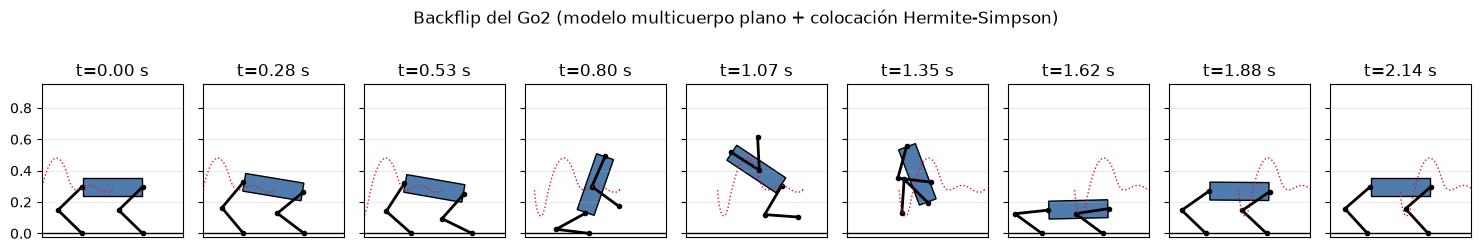

In [9]:
COL = ["#cfe8ff", "#ffe3c2", "#e6e6e6", "#cfe8ff"]


def sombrear(ax):
    for j in range(NF):
        ax.axvspan(lim[j], lim[j + 1], color=COL[j], alpha=0.5, lw=0)


def dibujar_robot(ax, qv, col="k", alpha=1.0, lw=2):
    P = np.array(F_puntos(qv))
    E = np.array(F_esq(qv))
    ax.add_patch(Polygon(E[:, [0, 1, 3, 2]].T, closed=True, fc="#4f7cac", ec=col, alpha=alpha, lw=1))
    for a, b in ((0, 3), (3, 6)):
        ax.plot(P[0, a:b], P[1, a:b], "-o", color=col, lw=lw, ms=3, alpha=alpha)


fig, axs = plt.subplots(1, 9, figsize=(15, 2.8), sharey=True)
for a, t in zip(axs, np.linspace(0, t_n[-1], 9)):
    k = np.argmin(np.abs(t_n - t))
    dibujar_robot(a, x_n[:7, k])
    a.plot(cm_n[0], cm_n[1], ":", color="crimson", lw=1)
    a.axhline(0, color="k", lw=1)
    a.set(xlim=(x_n[0, k] - 0.45, x_n[0, k] + 0.45), ylim=(-0.02, 0.95), title=f"t={t_n[k]:.2f} s")
    a.set_aspect("equal"); a.set_xticks([])
fig.suptitle("Backflip del Go2 (modelo multicuerpo plano + colocación Hermite-Simpson)")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "p2_secuencia.png"), dpi=160); plt.show()

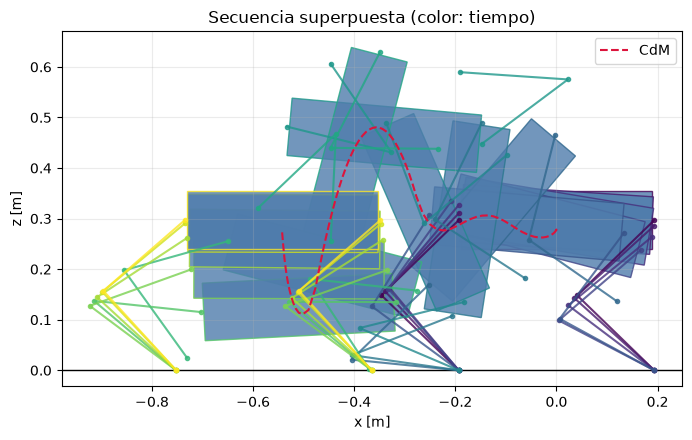

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axhline(0, color="k", lw=1)
ts = np.linspace(0, t_n[-1], 16)
for n, t in enumerate(ts):
    k = np.argmin(np.abs(t_n - t))
    dibujar_robot(ax, x_n[:7, k], col=plt.get_cmap("viridis")(n / (len(ts) - 1)), alpha=0.8, lw=1.5)
ax.plot(cm_n[0], cm_n[1], "--", color="crimson", label="CdM")
ax.set(xlabel="x [m]", ylabel="z [m]", title="Secuencia superpuesta (color: tiempo)")
ax.set_aspect("equal"); ax.legend(); fig.tight_layout()
fig.savefig(os.path.join(FIG, "p2_estroboscopica.png"), dpi=160); plt.show()

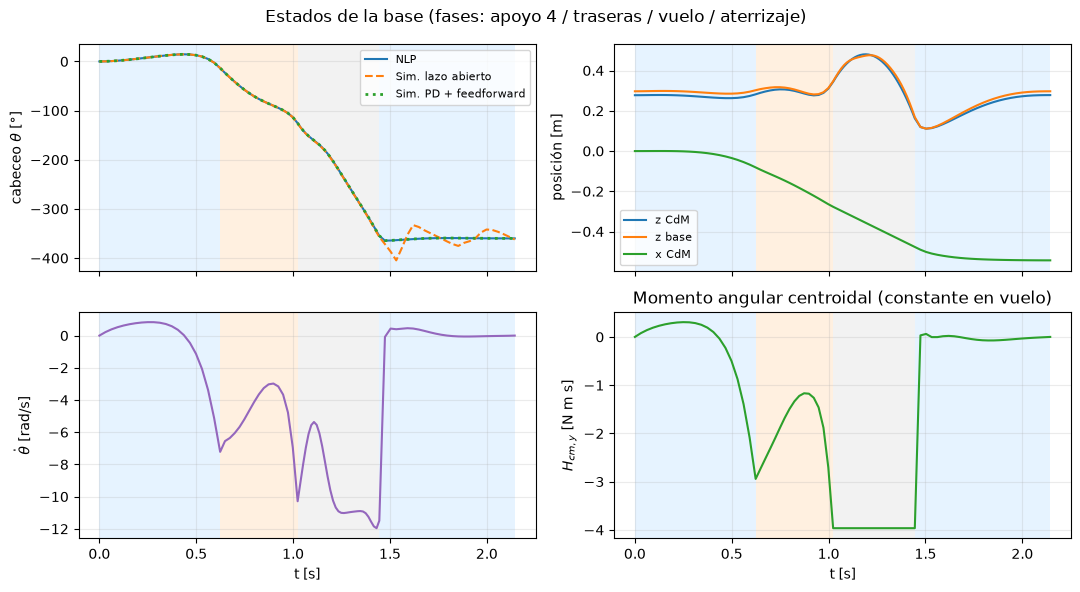

In [11]:
fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for a in axs.flat:
    sombrear(a)
axs[0, 0].plot(t_n, np.degrees(x_n[2]), label="NLP")
axs[0, 0].plot(t_s, np.degrees(x_s[2]), "--", label="Sim. lazo abierto")
axs[0, 0].plot(t_s, np.degrees(x_pd[2]), ":", lw=2, label="Sim. PD + feedforward")
axs[0, 0].set(ylabel="cabeceo $\\theta$ [°]"); axs[0, 0].legend(fontsize=8)
axs[0, 1].plot(t_n, cm_n[1], label="z CdM"); axs[0, 1].plot(t_n, x_n[1], label="z base")
axs[0, 1].plot(t_n, cm_n[0], label="x CdM"); axs[0, 1].set(ylabel="posición [m]"); axs[0, 1].legend(fontsize=8)
axs[1, 0].plot(t_n, x_n[9], color="tab:purple"); axs[1, 0].set(ylabel="$\\dot\\theta$ [rad/s]", xlabel="t [s]")
axs[1, 1].plot(t_n, H_n, color="tab:green")
axs[1, 1].set(ylabel="$H_{cm,y}$ [N m s]", xlabel="t [s]", title="Momento angular centroidal (constante en vuelo)")
fig.suptitle("Estados de la base (fases: apoyo 4 / traseras / vuelo / aterrizaje)")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "p2_estados.png"), dpi=160); plt.show()

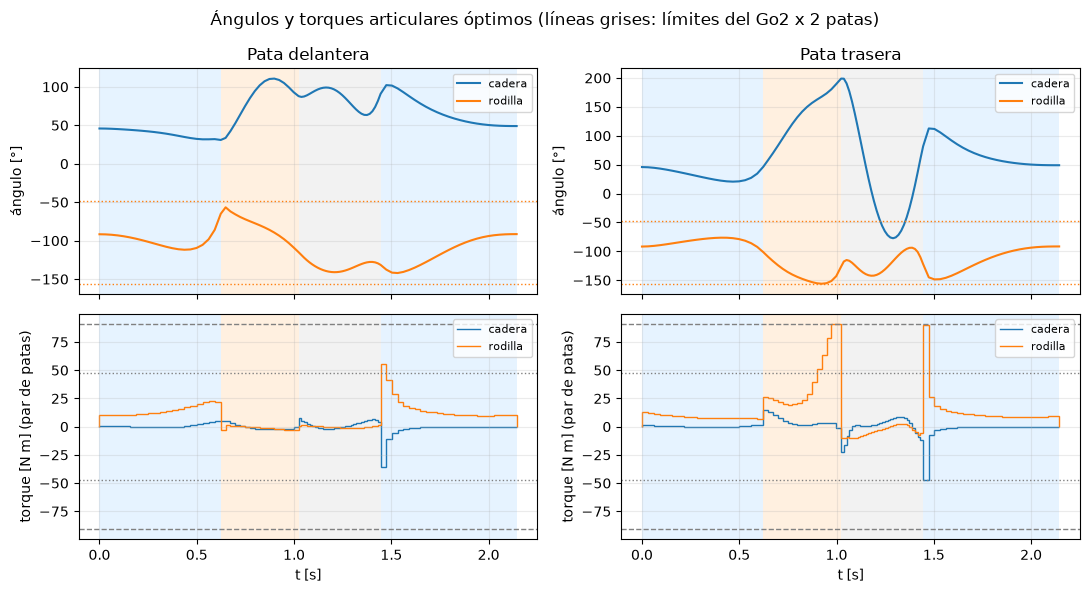

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for c, (nom, iq) in enumerate((("delantera", 3), ("trasera", 5))):
    for a in axs[:, c]:
        sombrear(a)
    axs[0, c].plot(t_n, np.degrees(x_n[iq]), label="cadera")
    axs[0, c].plot(t_n, np.degrees(x_n[iq + 1]), label="rodilla")
    axs[0, c].axhline(np.degrees(Q_MIN[1]), color="tab:orange", ls=":", lw=1)
    axs[0, c].axhline(np.degrees(Q_MAX[1]), color="tab:orange", ls=":", lw=1)
    axs[0, c].set(title=f"Pata {nom}", ylabel="ángulo [°]"); axs[0, c].legend(fontsize=8)
    j = 0 if iq == 3 else 2
    axs[1, c].stairs(u_n[j], t_n, label="cadera"); axs[1, c].stairs(u_n[j + 1], t_n, label="rodilla")
    for v, ls in ((TAU_MAX[0], ":"), (TAU_MAX[1], "--")):
        axs[1, c].axhline(v, color="gray", ls=ls, lw=1); axs[1, c].axhline(-v, color="gray", ls=ls, lw=1)
    axs[1, c].set(ylabel="torque [N m] (par de patas)", xlabel="t [s]"); axs[1, c].legend(fontsize=8)
fig.suptitle("Ángulos y torques articulares óptimos (líneas grises: límites del Go2 x 2 patas)")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "p2_articulaciones.png"), dpi=160); plt.show()

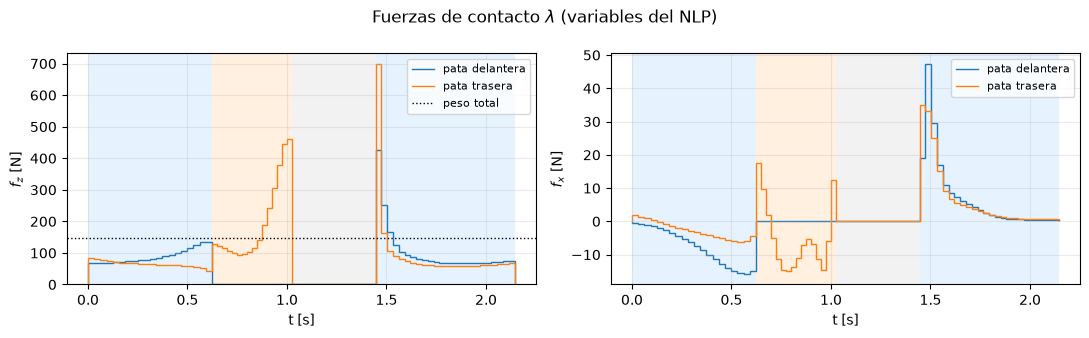

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for a, (j, nom) in zip(axs, ((1, "$f_z$"), (0, "$f_x$"))):
    sombrear(a)
    a.stairs(lam_n[j], t_n, label="pata delantera"); a.stairs(lam_n[j + 2], t_n, label="pata trasera")
    a.set(xlabel="t [s]", ylabel=f"{nom} [N]")
axs[0].axhline(M_TOT * g, color="k", ls=":", lw=1, label="peso total")
axs[0].legend(fontsize=8); axs[1].legend(fontsize=8)
fig.suptitle("Fuerzas de contacto $\\lambda$ (variables del NLP)")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "p2_fuerzas.png"), dpi=160); plt.show()

**Análisis.** La solución reproduce la estrategia de los backflips de robots reales: las cuatro patas empujan levantando la nariz; las delanteras despegan y las traseras completan el impulso (fuerzas normales de hasta ~3 $mg$, con componente tangencial), generando el momento angular necesario. En vuelo, el momento angular centroidal es constante, pero $\dot\theta$ cambia porque el robot **recoge y extiende las patas** para modificar su inercia. Aterriza con un pequeño sobregiro que absorbe en la fase de apoyo, terminando en reposo y en postura nominal con $\theta=-360^\circ$. Los torques llegan a los límites del actuador en el impulso y al aterrizar, como se espera en un movimiento tan explosivo.

## 9. Animación

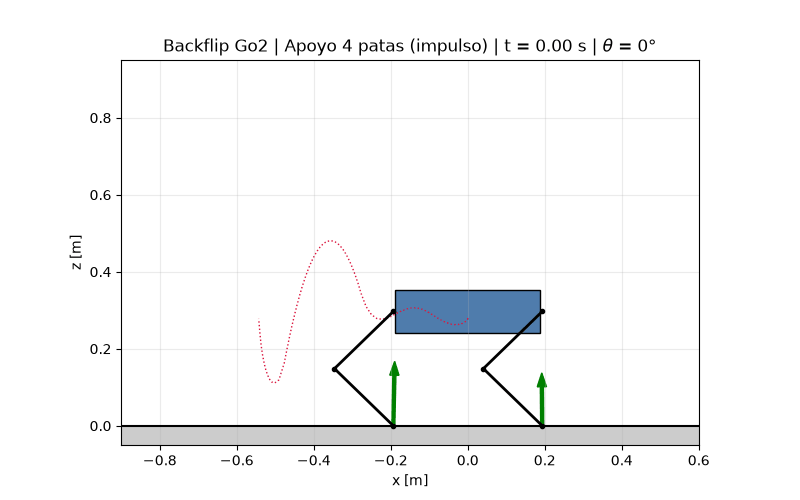

In [14]:
fps = 30
t_anim = np.r_[np.linspace(0, t_n[-1], int(fps * t_n[-1]) + 1), np.full(12, t_n[-1])]
fig, ax = plt.subplots(figsize=(8, 5))


def interp_q(t):
    return np.array([np.interp(t, t_n, x_n[j]) for j in range(7)])


def cuadro(n):
    t = t_anim[n]
    ax.cla()
    ax.axhline(0, color="k", lw=1.5)
    ax.fill_between([-1.5, 1.5], -0.05, 0, color="#cccccc")
    ax.plot(cm_n[0], cm_n[1], ":", color="crimson", lw=1)
    qv = interp_q(t)
    dibujar_robot(ax, qv)
    k = min(np.searchsorted(t_n, t, side="right") - 1, len(modo_n) - 1)
    P = np.array(F_puntos(qv))
    for j, ip in ((0, 2), (2, 5)):
        if lam_n[j + 1, k] > 1:
            ax.arrow(P[0, ip], P[1, ip], lam_n[j, k] / 500, lam_n[j + 1, k] / 500, color="green",
                     width=0.008, length_includes_head=True)
    ax.set(xlim=(-0.9, 0.6), ylim=(-0.05, 0.95), xlabel="x [m]", ylabel="z [m]",
           title=f"Backflip Go2 | {FASES[modo_n[k]]['nombre']} | t = {t:.2f} s | "
                 f"$\\theta$ = {np.degrees(qv[2]):.0f}°")
    ax.set_aspect("equal")
    return []


anim = FuncAnimation(fig, cuadro, frames=len(t_anim), interval=1000 / fps)
ruta_gif = os.path.join(FIG, "p2_backflip.gif")
anim.save(ruta_gif, writer=PillowWriter(fps=fps))
plt.close(fig)
display(Image(filename=ruta_gif))